<a href="https://colab.research.google.com/github/sharonoush/energy-ai-project/blob/main/wind_analysis_updated.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd

wind = pd.read_csv("ods031_offshore_2024_2025.csv")
wind.head()

,datetime,measured,dayaheadforecast,monitoredcapacity
0,2024-01-02T11:00:00+01:00,1644.27,2061.3,2262.1
1,2024-01-02T10:30:00+01:00,1532.84,2075.2,2262.1
2,2024-01-02T09:15:00+01:00,2006.62,2084.2,2262.1
3,2024-01-02T09:00:00+01:00,2057.67,2090.3,2262.1
4,2024-01-02T07:15:00+01:00,2080.83,2140.6,2262.1


In [2]:
wind["datetime"] = pd.to_datetime(wind["datetime"], utc=True)  # convert text to real timestamps
wind = wind.sort_values("datetime").reset_index(drop=True)     # rows came in random order, so sort by time
wind["monitoredcapacity"] = wind["monitoredcapacity"].ffill()  # fill the 116 missing values with the previous value

# Forecast error = forecast - actual (positive = forecast was too high)
wind["error_MW"] = wind["dayaheadforecast"] - wind["measured"]
wind["error_pct"] = wind["error_MW"] / wind["monitoredcapacity"] * 100

print("Mean error (bias):", wind["error_MW"].mean().round(1), "MW")
print("Mean absolute error (MAE):", wind["error_MW"].abs().mean().round(1), "MW")
print("MAE as % of installed capacity:", wind["error_pct"].abs().mean().round(2), "%")

Mean error (bias): 20.9 MW
Mean absolute error (MAE): 152.2 MW
MAE as % of installed capacity: 6.73 %


In [3]:
# Each row is 15 minutes = 0.25 hour, so energy (MWh) = power (MW) x 0.25
wind["energy_MWh"] = wind["measured"] * 0.25
wind["abs_error_MWh"] = wind["error_MW"].abs() * 0.25
wind["year"] = wind["datetime"].dt.tz_convert("Europe/Brussels").dt.year

yearly = wind.groupby("year").agg(
    energy_MWh=("energy_MWh", "sum"),
    abs_error_MWh=("abs_error_MWh", "sum"),
    capacity_MW=("monitoredcapacity", "mean"),
    hours=("energy_MWh", "size"),
)
yearly["hours"] = yearly["hours"] * 0.25                       # number of rows -> hours
yearly["capacity_factor_%"] = yearly["energy_MWh"] / (yearly["capacity_MW"] * yearly["hours"]) * 100

# Scale to Rentel (308.7 MW) as the example wind farm
rentel_share = 308.7 / yearly["capacity_MW"]
yearly["rentel_energy_MWh"] = yearly["energy_MWh"] * rentel_share

print(yearly.round(1))

      energy_MWh  abs_error_MWh  capacity_MW   hours  capacity_factor_%  \
year                                                                      
2024   7071028.9      1348141.9       2262.1  8784.0               35.6   
2025   6768843.6      1322219.5       2261.9  8760.0               34.2   

      rentel_energy_MWh  
year                     
2024           964955.8  
2025           923806.4  


In [4]:
# Peek at the first rows of the two imbalance price datasets
base = "https://opendata.elia.be/api/explore/v2.1/catalog/datasets/{}/exports/csv?limit=3&delimiter=;"

for ds in ["ods047", "ods134"]:
    peek = pd.read_csv(base.format(ds), sep=";")
    print(ds)
    print(peek.columns.tolist())
    print(peek.head(3))
    print()

ods047
['datetime', 'qualitystatus', 'resolutioncode', 'netregulationvolume', 'systemimbalance', 'alpha', 'marginalincrementalprice', 'marginaldecrementalprice', 'strategicreserveprice', 'positiveimbalanceprice', 'negativeimbalanceprice']
                    datetime qualitystatus resolutioncode  \
0  2024-05-21T21:45:00+00:00     Validated          PT15M   
1  2024-05-21T21:30:00+00:00     Validated          PT15M   
2  2024-05-21T21:15:00+00:00     Validated          PT15M   

   netregulationvolume  systemimbalance  alpha  marginalincrementalprice  \
0               56.474          -65.454    0.0                     70.00   
1               84.264         -112.370    0.0                     94.89   
2               63.907          -92.096    0.0                    120.88   

   marginaldecrementalprice  strategicreserveprice  positiveimbalanceprice  \
0                     29.76                    NaN                   70.00   
1                     30.00                    NaN     

In [5]:
from urllib.parse import urlencode

def download_elia(dataset, start, end):
    """Download one Elia dataset between two dates as a DataFrame."""
    url = f"https://opendata.elia.be/api/explore/v2.1/catalog/datasets/{dataset}/exports/csv"
    params = {"where": f"datetime >= '{start}' and datetime < '{end}'", "delimiter": ";"}
    return pd.read_csv(url + "?" + urlencode(params), sep=";")

old = download_elia("ods047", "2024-01-01", "2024-05-22")   # old design
new = download_elia("ods134", "2024-05-22", "2026-01-01")   # new design

old.to_csv("ods047_imbalance_2024.csv", index=False)
new.to_csv("ods134_imbalance_2024_2025.csv", index=False)

print("old:", old.shape, "new:", new.shape)
print("resolution codes in new:", new["resolutioncode"].unique())
print("price columns in new:", [c for c in new.columns if "price" in c])

old: (13624, 11) new: (56544, 10)
resolution codes in new: ['PT15M']
price columns in new: ['marginalincrementalprice', 'marginaldecrementalprice', 'imbalanceprice']


In [6]:
# 1. Put old and new prices into one table with the same column name
old["price"] = old["positiveimbalanceprice"]   # single price: positive = negative
new["price"] = new["imbalanceprice"]
prices = pd.concat([old[["datetime", "price"]], new[["datetime", "price"]]])
prices["datetime"] = pd.to_datetime(prices["datetime"], utc=True)
prices = prices.drop_duplicates("datetime")

# 2. Match each wind quarter-hour with its imbalance price
df = wind.merge(prices, on="datetime", how="inner")
print("matched rows:", len(df), "of", len(wind))

# 3. Imbalance = actual - forecast (positive = we produced MORE than sold)
df["imbalance_MWh"] = (df["measured"] - df["dayaheadforecast"]) * 0.25
df["settlement_EUR"] = df["imbalance_MWh"] * df["price"]   # + = received, - = paid

# 4. Average price when we are short vs long
short = df[df["imbalance_MWh"] < 0]
long = df[df["imbalance_MWh"] > 0]
print("avg price when wind is SHORT (we buy):", short["price"].mean().round(1), "EUR/MWh")
print("avg price when wind is LONG (we sell):", long["price"].mean().round(1), "EUR/MWh")

# 5. Yearly summary
summary = df.groupby("year").agg(
    net_imbalance_MWh=("imbalance_MWh", "sum"),
    settlement_EUR=("settlement_EUR", "sum"),
    avg_price=("price", "mean"),
)
summary.round(0)

matched rows: 70164 of 70176
avg price when wind is SHORT (we buy): 87.0 EUR/MWh
avg price when wind is LONG (we sell): 61.7 EUR/MWh


,net_imbalance_MWh,settlement_EUR,avg_price
year,,,
2024,-258107.0,-51360630.0,70.0
2025,-108779.0,-34509874.0,83.0


## Figure 1: Day-ahead forecast vs actual output (one week)

This figure compares the actual offshore wind output (`measured`) with Elia's
day-ahead forecast (`dayaheadforecast`) for one week, at 15-minute resolution.
The shaded area between the two lines is the forecast error.

- Data: Elia Open Data ods031, all Belgian offshore wind farms (~2.26 GW)
- Forecast error = forecast − actual (positive = forecast too high)

**Observation:** _(write what you see: when is the error largest? sudden drops? storms?)_

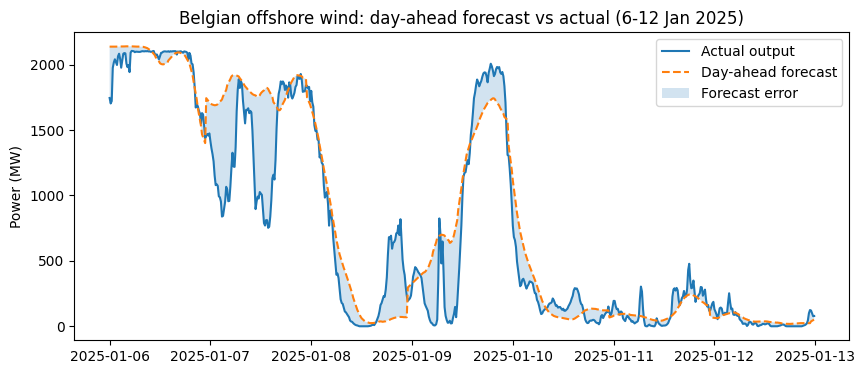

In [7]:
import matplotlib.pyplot as plt

# Pick one week (change the dates to try other weeks)
start = pd.Timestamp("2025-01-06", tz="UTC")
end = pd.Timestamp("2025-01-13", tz="UTC")
week = wind[(wind["datetime"] >= start) & (wind["datetime"] < end)]

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(week["datetime"], week["measured"], label="Actual output")
ax.plot(week["datetime"], week["dayaheadforecast"], label="Day-ahead forecast", linestyle="--")
ax.fill_between(week["datetime"], week["measured"], week["dayaheadforecast"],
                alpha=0.2, label="Forecast error")
ax.set_ylabel("Power (MW)")
ax.set_title("Belgian offshore wind: day-ahead forecast vs actual (6-12 Jan 2025)")
ax.legend()
fig.savefig("fig1_forecast_vs_actual.png", dpi=300, bbox_inches="tight")
plt.show()

## Figure 2: Monthly imbalance settlement (2024–2025)

When actual output differs from the day-ahead forecast, the difference
(imbalance) is settled with Elia at the imbalance price.
Settlement per quarter-hour = (actual − forecast) × 0.25 h × imbalance price.
Red bars = months where wind farms paid in total; green = received.

- Prices: Elia ods047 (until 21 May 2024) and ods134 (from 22 May 2024, new design)
- Assumption: the wind farms sell exactly Elia's day-ahead forecast the day before
- Note: the net settlement includes the energy value of the net shortfall,
  so it is an upper estimate of the pure "forecast error cost"

**Observation:** _(which months are worst? winter vs summer? 2024 vs 2025?)_

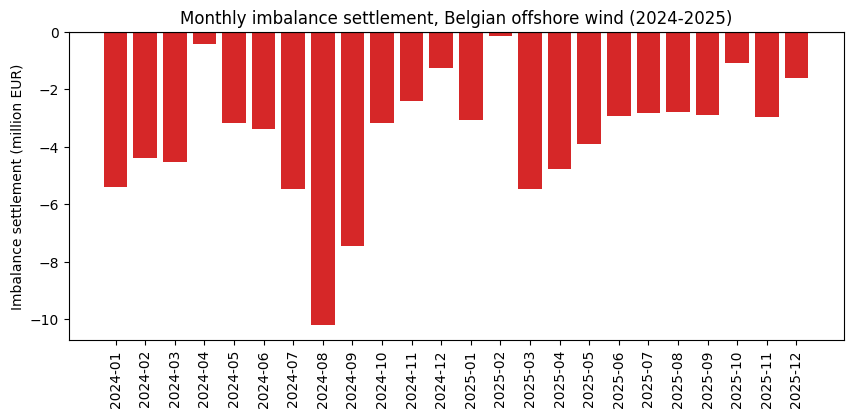

In [8]:
# Sum the settlement per month (in million EUR), using Belgian local time
monthly = (df.set_index(df["datetime"].dt.tz_convert("Europe/Brussels"))["settlement_EUR"]
             .resample("MS").sum() / 1e6)

colors = ["tab:red" if v < 0 else "tab:green" for v in monthly]
fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(monthly.index.strftime("%Y-%m"), monthly.values, color=colors)
ax.axhline(0, color="black", linewidth=0.8)
ax.set_ylabel("Imbalance settlement (million EUR)")
ax.set_title("Monthly imbalance settlement, Belgian offshore wind (2024-2025)")
ax.tick_params(axis="x", rotation=90)
fig.savefig("fig2_monthly_settlement.png", dpi=300, bbox_inches="tight")
plt.show()

### Conclusions
1. The day-ahead forecast is fairly accurate but not perfect: the average error
   is about 150 MW, or 6.7% of installed capacity. The bias is small (+21 MW),
   so most errors are random, not a systematic over- or under-forecast.
2. Imbalance prices work against wind. When wind produces less than forecast,
   the system is usually short too, so the price is high (87 €/MWh on average).
   When wind produces more, the system is usually long, so the price is low
   (62 €/MWh). Because Belgian offshore wind is large, its own errors push the
   price in the unfavourable direction.
3. For the whole Belgian offshore fleet the net imbalance settlement was about
   −51 M€ in 2024 and −35 M€ in 2025 (5–7 € per MWh produced). Scaled to
   Rentel this is roughly 5–7 M€ per year, about 2–3.5% of its revenue.
   A more accurate forecast (for example with AI) could reduce this cost,
   which links the data flow (forecast) directly to the money flow.

### Limitations
1. We assume the wind farm sells exactly Elia's day-ahead forecast. Real farms
   may use their own forecasts or trade again in the intraday market.
2. Rentel's numbers are scaled from the whole offshore fleet by capacity
   (308.7 / ~2262 MW), not measured for Rentel itself.
3. The net settlement also includes the value of the energy that was sold but
   not produced, so it overestimates the pure cost of forecast errors.
   A cleaner estimate would compare with the day-ahead market price.
4. Only two years (2024–2025) are analysed, and the imbalance price design
   changed on 22 May 2024.

In [9]:
print(df.columns.tolist())
print(df.head())
print(df.dtypes)

['datetime', 'measured', 'dayaheadforecast', 'monitoredcapacity', 'error_MW', 'error_pct', 'energy_MWh', 'abs_error_MWh', 'year', 'price', 'imbalance_MWh', 'settlement_EUR']
                   datetime  measured  dayaheadforecast  monitoredcapacity  \
0 2024-01-01 00:00:00+00:00   2077.74            2182.3             2262.1   
1 2024-01-01 00:15:00+00:00   2089.99            2182.3             2262.1   
2 2024-01-01 00:30:00+00:00   2101.92            2182.1             2262.1   
3 2024-01-01 00:45:00+00:00   2099.31            2181.8             2262.1   
4 2024-01-01 01:00:00+00:00   2101.68            2181.1             2262.1   

   error_MW  error_pct  energy_MWh  abs_error_MWh  year   price  \
0    104.56   4.622254    519.4350        26.1400  2024  211.86   
1     92.31   4.080721    522.4975        23.0775  2024  121.56   
2     80.18   3.544494    525.4800        20.0450  2024  118.70   
3     82.49   3.646612    524.8275        20.6225  2024  117.80   
4     79.42   3.510897

In [10]:
import numpy as np
import pandas as pd

# Work on a copy
ml_df = df.copy()

# Ensure chronological order
ml_df = ml_df.sort_values("datetime").reset_index(drop=True)

# Extract time features
ml_df["hour"] = ml_df["datetime"].dt.hour
ml_df["dayofyear"] = ml_df["datetime"].dt.dayofyear
ml_df["dayofweek"] = ml_df["datetime"].dt.dayofweek

# Cyclical encoding of time features
ml_df["hour_sin"] = np.sin(2 * np.pi * ml_df["hour"] / 24)
ml_df["hour_cos"] = np.cos(2 * np.pi * ml_df["hour"] / 24)

ml_df["day_sin"] = np.sin(2 * np.pi * ml_df["dayofyear"] / 365.25)
ml_df["day_cos"] = np.cos(2 * np.pi * ml_df["dayofyear"] / 365.25)

# Historical generation features
ml_df["lag_96"] = ml_df["measured"].shift(96)
ml_df["lag_192"] = ml_df["measured"].shift(192)
ml_df["lag_672"] = ml_df["measured"].shift(672)

# Remove rows without historical data
ml_df = ml_df.dropna().reset_index(drop=True)

print("Dataset shape:", ml_df.shape)
print(ml_df.head())

Dataset shape: (69492, 22)
                   datetime  measured  dayaheadforecast  monitoredcapacity  \
0 2024-01-08 00:00:00+00:00   2004.06            1828.0             2262.1   
1 2024-01-08 00:15:00+00:00   2017.45            1832.5             2262.1   
2 2024-01-08 00:30:00+00:00   1988.88            1827.4             2262.1   
3 2024-01-08 00:45:00+00:00   2033.92            1812.8             2262.1   
4 2024-01-08 01:00:00+00:00   2038.35            1789.5             2262.1   

   error_MW  error_pct  energy_MWh  abs_error_MWh  year   price  ...  hour  \
0   -176.06  -7.783033    501.0150        44.0150  2024  -25.64  ...     0   
1   -184.95  -8.176031    504.3625        46.2375  2024  109.84  ...     0   
2   -161.48  -7.138500    497.2200        40.3700  2024  -80.21  ...     0   
3   -221.12  -9.774988    508.4800        55.2800  2024  -32.09  ...     0   
4   -248.85 -11.000840    509.5875        62.2125  2024  -26.87  ...     1   

   dayofyear  dayofweek  hour_sin  

In [11]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# Define input features
features = [
    "dayaheadforecast",
    "hour_sin", "hour_cos",
    "day_sin", "day_cos",
    "dayofweek",
    "lag_96", "lag_192", "lag_672"
]

target = "measured"

# Chronological train-test split
train = ml_df[ml_df["year"] == 2024]
test = ml_df[ml_df["year"] == 2025]

X_train = train[features]
y_train = train[target]

X_test = test[features]
y_test = test[target]

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 34452
Testing samples: 35040


In [12]:
# Initialise model
rf_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=15,
    min_samples_split=10,
    random_state=42,
    n_jobs=-1
)

# Train
rf_model.fit(X_train, y_train)

# Predict 2025 generation
y_pred = rf_model.predict(X_test)

print("Model training complete!")

Model training complete!


In [13]:
# Elia's forecast for the same test period
elia_pred = X_test["dayaheadforecast"]

# Calculate metrics
results = pd.DataFrame({
    "Model": ["Elia Day-Ahead Forecast", "Random Forest"],
    "MAE (MW)": [
        mean_absolute_error(y_test, elia_pred),
        mean_absolute_error(y_test, y_pred)
    ],
    "RMSE (MW)": [
        np.sqrt(mean_squared_error(y_test, elia_pred)),
        np.sqrt(mean_squared_error(y_test, y_pred))
    ]
})

print(results.round(2))

# Percentage improvement in MAE
elia_mae = mean_absolute_error(y_test, elia_pred)
model_mae = mean_absolute_error(y_test, y_pred)

improvement = (elia_mae - model_mae) / elia_mae * 100

print(f"\nMAE improvement: {improvement:.2f}%")

                     Model  MAE (MW)  RMSE (MW)
0  Elia Day-Ahead Forecast    150.94     227.96
1            Random Forest    182.36     263.88

MAE improvement: -20.82%


In [14]:
# Target: forecast error
y_train_error = (
    train["measured"] - train["dayaheadforecast"]
)

# Train a new Random Forest
error_model = RandomForestRegressor(
    n_estimators=200,
    max_depth=15,
    min_samples_split=10,
    random_state=42,
    n_jobs=-1
)

error_model.fit(X_train, y_train_error)

# Predict forecast error for 2025
predicted_error = error_model.predict(X_test)

# Correct Elia's forecast
corrected_pred = (
    X_test["dayaheadforecast"].values + predicted_error
)

# Evaluate
print("Corrected forecast MAE:",
      mean_absolute_error(y_test, corrected_pred))

print("Corrected forecast RMSE:",
      np.sqrt(mean_squared_error(y_test, corrected_pred)))

Corrected forecast MAE: 180.20203922204377
Corrected forecast RMSE: 258.69658799695316


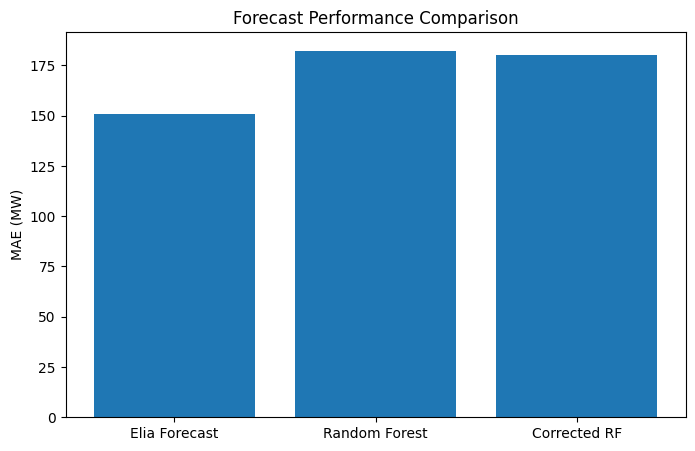

In [15]:
import matplotlib.pyplot as plt

models = ["Elia Forecast", "Random Forest", "Corrected RF"]
maes = [
    mean_absolute_error(y_test, elia_pred),
    mean_absolute_error(y_test, y_pred),
    mean_absolute_error(y_test, corrected_pred)
]

plt.figure(figsize=(8, 5))
plt.bar(models, maes)
plt.ylabel("MAE (MW)")
plt.title("Forecast Performance Comparison")
plt.show()

dayaheadforecast    0.922565
day_sin             0.014785
day_cos             0.013565
lag_672             0.010321
lag_96              0.010098
lag_192             0.009384
hour_sin            0.006874
dayofweek           0.006478
hour_cos            0.005930
dtype: float64


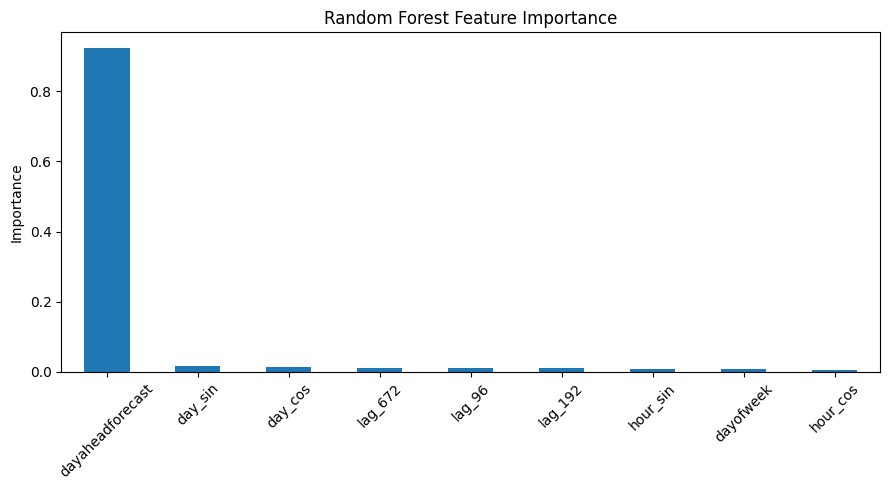

In [16]:
importance = pd.Series(
    rf_model.feature_importances_,
    index=features
).sort_values(ascending=False)

print(importance)

importance.plot(kind="bar", figsize=(9, 5))
plt.title("Random Forest Feature Importance")
plt.ylabel("Importance")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [17]:
for name, pred in [
    ("Random Forest", y_pred),
    ("Corrected Random Forest", corrected_pred)
]:
    mae = mean_absolute_error(y_test, pred)
    rmse = np.sqrt(mean_squared_error(y_test, pred))

    print(f"{name}:")
    print(f"MAE deterioration: {(mae / elia_mae - 1) * 100:.2f}%")
    print(f"RMSE deterioration: {(rmse / np.sqrt(mean_squared_error(y_test, elia_pred)) - 1) * 100:.2f}%")
    print()

Random Forest:
MAE deterioration: 20.82%
RMSE deterioration: 15.76%

Corrected Random Forest:
MAE deterioration: 19.39%
RMSE deterioration: 13.48%



In [18]:
import requests
import pandas as pd

url = "https://historical-forecast-api.open-meteo.com/v1/forecast"

params = {
    "latitude": 51.6,
    "longitude": 2.9,
    "start_date": "2025-01-01",
    "end_date": "2025-01-07",
    "hourly": [
        "wind_speed_100m",
        "wind_direction_100m",
        "temperature_100m"
    ],
    "timezone": "UTC"
}

response = requests.get(url, params=params)
print(response.status_code)
print(response.text[:1000])

200
{"latitude":51.592,"longitude":2.8999999,"generationtime_ms":208.21547508239746,"utc_offset_seconds":0,"timezone":"GMT","timezone_abbreviation":"GMT","elevation":0.0,"hourly_units":{"time":"iso8601","wind_speed_100m":"km/h","wind_direction_100m":"°","temperature_100m":"°C"},"hourly":{"time":["2025-01-01T00:00","2025-01-01T01:00","2025-01-01T02:00","2025-01-01T03:00","2025-01-01T04:00","2025-01-01T05:00","2025-01-01T06:00","2025-01-01T07:00","2025-01-01T08:00","2025-01-01T09:00","2025-01-01T10:00","2025-01-01T11:00","2025-01-01T12:00","2025-01-01T13:00","2025-01-01T14:00","2025-01-01T15:00","2025-01-01T16:00","2025-01-01T17:00","2025-01-01T18:00","2025-01-01T19:00","2025-01-01T20:00","2025-01-01T21:00","2025-01-01T22:00","2025-01-01T23:00","2025-01-02T00:00","2025-01-02T01:00","2025-01-02T02:00","2025-01-02T03:00","2025-01-02T04:00","2025-01-02T05:00","2025-01-02T06:00","2025-01-02T07:00","2025-01-02T08:00","2025-01-02T09:00","2025-01-02T10:00","2025-01-02T11:00","2025-01-02T12:00",

In [19]:
import requests
import pandas as pd

url = "https://historical-forecast-api.open-meteo.com/v1/forecast"

params = {
    "latitude": 51.6,
    "longitude": 2.9,
    "start_date": "2024-01-01",
    "end_date": "2025-12-31",
    "hourly": [
        "wind_speed_100m",
        "wind_direction_100m",
        "temperature_100m"
    ],
    "timezone": "UTC"
}

response = requests.get(url, params=params)
response.raise_for_status()

weather = pd.DataFrame(response.json()["hourly"])
weather["time"] = pd.to_datetime(weather["time"], utc=True)

print(weather.shape)
print(weather.head())

(17544, 4)
                       time  wind_speed_100m  wind_direction_100m  \
0 2024-01-01 00:00:00+00:00             74.2                  233   
1 2024-01-01 01:00:00+00:00             69.5                  235   
2 2024-01-01 02:00:00+00:00             65.7                  243   
3 2024-01-01 03:00:00+00:00             62.0                  246   
4 2024-01-01 04:00:00+00:00             63.0                  253   

   temperature_100m  
0               NaN  
1               NaN  
2               NaN  
3               NaN  
4               NaN  


In [20]:
print("Date range:")
print(weather["time"].min(), "to", weather["time"].max())

print("\nMissing values:")
print(weather.isna().sum())

print("\nWeather statistics:")
print(weather.describe())

Date range:
2024-01-01 00:00:00+00:00 to 2025-12-31 23:00:00+00:00

Missing values:
time                      0
wind_speed_100m           0
wind_direction_100m       0
temperature_100m       4248
dtype: int64

Weather statistics:
       wind_speed_100m  wind_direction_100m  temperature_100m
count     17544.000000         17544.000000      13296.000000
mean         33.551214           189.238885         12.312583
std          15.857452            93.915355          5.162470
min           0.400000             0.000000         -0.900000
25%          22.000000           115.000000          8.200000
50%          32.400000           208.000000         12.900000
75%          44.000000           253.000000         16.500000
max          97.300000           360.000000         30.600000


In [21]:
import numpy as np

weather["wind_speed_ms"] = weather["wind_speed_100m"] / 3.6

weather["wind_dir_sin"] = np.sin(
    np.radians(weather["wind_direction_100m"])
)

weather["wind_dir_cos"] = np.cos(
    np.radians(weather["wind_direction_100m"])
)

weather = weather[
    ["time", "wind_speed_ms", "wind_dir_sin", "wind_dir_cos"]
]

print(weather.head())

                       time  wind_speed_ms  wind_dir_sin  wind_dir_cos
0 2024-01-01 00:00:00+00:00      20.611111     -0.798636     -0.601815
1 2024-01-01 01:00:00+00:00      19.305556     -0.819152     -0.573576
2 2024-01-01 02:00:00+00:00      18.250000     -0.891007     -0.453990
3 2024-01-01 03:00:00+00:00      17.222222     -0.913545     -0.406737
4 2024-01-01 04:00:00+00:00      17.500000     -0.956305     -0.292372


In [22]:
ml_df_weather = ml_df.copy()

ml_df_weather = pd.merge_asof(
    ml_df_weather.sort_values("datetime"),
    weather.sort_values("time"),
    left_on="datetime",
    right_on="time",
    direction="backward"
)

ml_df_weather = ml_df_weather.drop(columns=["time"])

print("Dataset shape:", ml_df_weather.shape)
print(ml_df_weather[
    ["datetime", "measured", "wind_speed_ms",
     "wind_dir_sin", "wind_dir_cos"]
].head(8))

Dataset shape: (69492, 25)
                   datetime  measured  wind_speed_ms  wind_dir_sin  \
0 2024-01-08 00:00:00+00:00   2004.06      13.527778      0.788011   
1 2024-01-08 00:15:00+00:00   2017.45      13.527778      0.788011   
2 2024-01-08 00:30:00+00:00   1988.88      13.527778      0.788011   
3 2024-01-08 00:45:00+00:00   2033.92      13.527778      0.788011   
4 2024-01-08 01:00:00+00:00   2038.35      13.722222      0.743145   
5 2024-01-08 01:15:00+00:00   2017.04      13.722222      0.743145   
6 2024-01-08 01:30:00+00:00   1996.51      13.722222      0.743145   
7 2024-01-08 01:45:00+00:00   1997.54      13.722222      0.743145   

   wind_dir_cos  
0      0.615661  
1      0.615661  
2      0.615661  
3      0.615661  
4      0.669131  
5      0.669131  
6      0.669131  
7      0.669131  


In [23]:
weather_features = features + [
    "wind_speed_ms",
    "wind_dir_sin",
    "wind_dir_cos"
]

train_weather = ml_df_weather[
    ml_df_weather["year"] == 2024
]

test_weather = ml_df_weather[
    ml_df_weather["year"] == 2025
]

X_train_weather = train_weather[weather_features]
y_train_weather = train_weather["measured"]

X_test_weather = test_weather[weather_features]
y_test_weather = test_weather["measured"]

weather_model = RandomForestRegressor(
    n_estimators=200,
    max_depth=15,
    min_samples_split=10,
    random_state=42,
    n_jobs=-1
)

weather_model.fit(X_train_weather, y_train_weather)

y_pred_weather = weather_model.predict(X_test_weather)

print("Weather-enhanced model trained!")

Weather-enhanced model trained!


In [24]:
results_weather = pd.DataFrame({
    "Model": [
        "Elia Day-Ahead",
        "Random Forest",
        "Corrected Random Forest",
        "Weather-Enhanced RF"
    ],
    "MAE (MW)": [
        mean_absolute_error(y_test_weather, X_test_weather["dayaheadforecast"]),
        mean_absolute_error(y_test, y_pred),
        mean_absolute_error(y_test, corrected_pred),
        mean_absolute_error(y_test_weather, y_pred_weather)
    ],
    "RMSE (MW)": [
        np.sqrt(mean_squared_error(y_test_weather, X_test_weather["dayaheadforecast"])),
        np.sqrt(mean_squared_error(y_test, y_pred)),
        np.sqrt(mean_squared_error(y_test, corrected_pred)),
        np.sqrt(mean_squared_error(y_test_weather, y_pred_weather))
    ]
})

print(results_weather.round(2))

                     Model  MAE (MW)  RMSE (MW)
0           Elia Day-Ahead    150.94     227.96
1            Random Forest    182.36     263.88
2  Corrected Random Forest    180.20     258.70
3      Weather-Enhanced RF    159.01     227.12


dayaheadforecast    0.850842
wind_speed_ms       0.095160
wind_dir_sin        0.008370
day_cos             0.007668
day_sin             0.006737
wind_dir_cos        0.006188
lag_672             0.005043
lag_96              0.004848
lag_192             0.004654
hour_cos            0.003885
hour_sin            0.003449
dayofweek           0.003157
dtype: float64


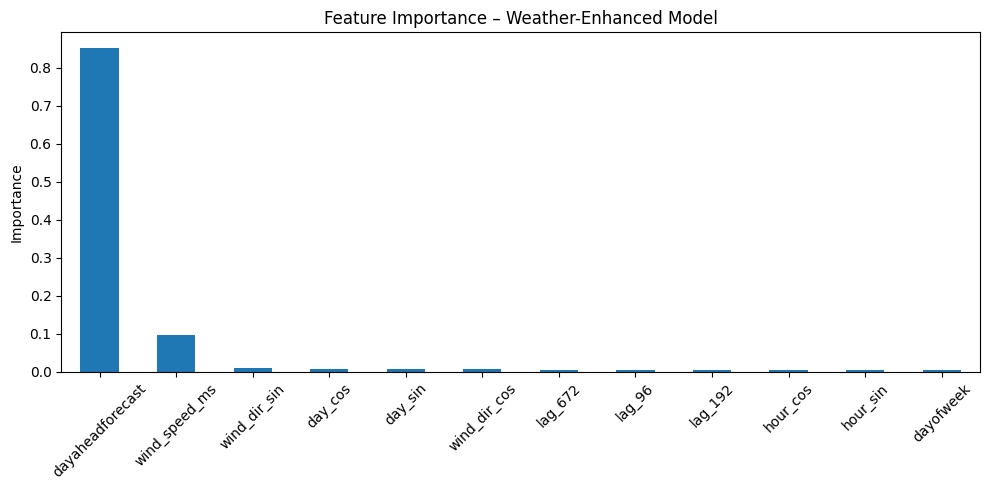

In [25]:
weather_importance = pd.Series(
    weather_model.feature_importances_,
    index=weather_features
).sort_values(ascending=False)

print(weather_importance)

weather_importance.plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Feature Importance – Weather-Enhanced Model")
plt.ylabel("Importance")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

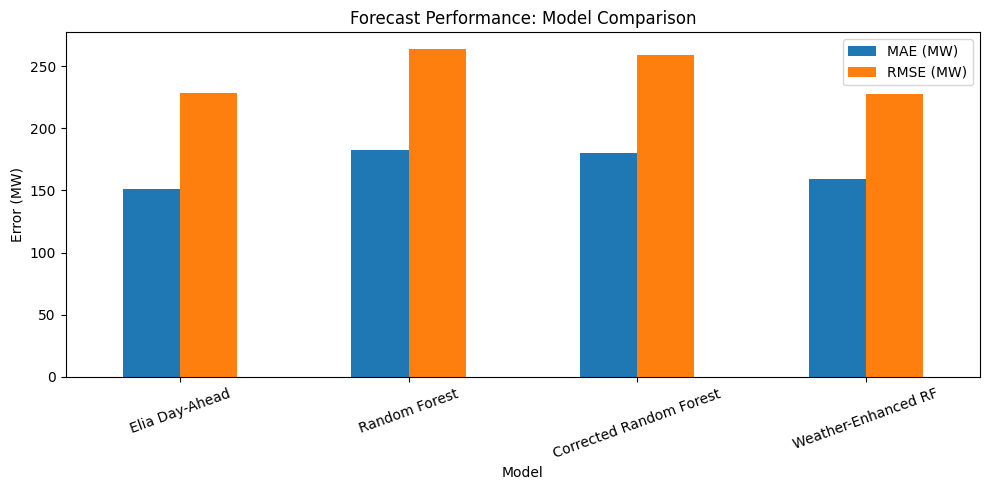

In [26]:
results_weather.set_index("Model")[["MAE (MW)", "RMSE (MW)"]].plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Forecast Performance: Model Comparison")
plt.ylabel("Error (MW)")
plt.xticks(rotation=20)
plt.legend()
plt.tight_layout()
plt.show()